**Author**: JW Debelius (justine.debelius@jhu.edu)<br>
**Project**: 017-Arg<br>
**Enviroment**: <br>
**Creation Date**:  November 2025

We're going to create a heatmap showing the 

In [1]:
import os

import biom
import numpy as np
import pandas as pd
import scipy
import skbio

from matplotlib import rcParams
import matplotlib.pyplot as plt
import matplotlib.colors as mpc
from matplotlib.ticker import StrMethodFormatter
import seaborn as sn

from qiime2 import Artifact, Metadata, Visualization

import qiime2.plugins.phylogeny.actions as q2_tree

%matplotlib inline
rcParams['font.sans-serif'] = ['Helvetica', 'Arial']
rcParams['pdf.fonttype'] = 42

/Users/jwd/miniconda3/envs/arg-amplicon-2025.7/lib/python3.10/site-packages/q2_demux/_summarize/_visualizer.py:11: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


# Data

In [2]:
meta = pd.read_csv('final-data/01.metadata/analysis_sample_meta.tsv',
                     sep='\t',
                     dtype=str)
meta.set_index('sample-id', inplace=True)

In [3]:
table_q2 = Artifact.load('final-data/02.tables/matched-species-gtdb.qza')

In [4]:
table_a = table_q2.view(biom.Table)
table_a.add_metadata(meta.to_dict(orient='index'), axis='sample')
table_a.filter(lambda v, id_, md: v.sum() >= 1e6, axis='sample')
    # .norm(axis='sample')
table_n = table_a.copy().norm(axis='sample')
table_id = table_n.collapse(lambda id_, md: md['host_subject_id'],
                            axis='sample',
                            norm=True)
table_avg = table_id.collapse(lambda id_, md: 'all',
                             axis='sample',
                             norm=True)
table_avg = table_avg.to_dataframe().sparse.to_dense()
table_avg.sort_values('all', ascending=False, inplace=True)
table_avg2 = table_avg.head(30)

In in ideal world, the features would be sorted phylogenetically. So, I'm going to load the three, and get the distance from the most abundant tip, and then from there, the distance from the furtherest clade, to see if we can 

In [52]:
tree_q2 = Artifact.load('final-data/02.tables/matched_tree_gtdb.qza')
taxa_q2 = Artifact.load('final-data/02.tables/matched-taxonomy-gtdb.qza')
taxa = taxa_q2.view(pd.DataFrame)
taxa_abund = taxa.loc[taxa['Taxon'].isin(table_avg2.index)].copy()
taxa_abund['abund'] = taxa_abund['Taxon'].replace(table_avg2['all'].astype(str)).astype(float)
taxa_abund['phylum'] = taxa_abund['Taxon'].apply(lambda x: x.split(';')[1])
taxa_abund.sort_values(['phylum', 'abund'], ascending=[True, False], inplace=True)
top_tip = taxa_abund.drop_duplicates('phylum', keep='first').index.values
top_tip = list(top_tip)

In [46]:
help(abund_order.sort_values)

Help on method sort_values in module pandas.core.frame:

sort_values(by: 'IndexLabel', *, axis: 'Axis' = 0, ascending: 'bool | list[bool] | tuple[bool, ...]' = True, inplace: 'bool' = False, kind: 'SortKind' = 'quicksort', na_position: 'str' = 'last', ignore_index: 'bool' = False, key: 'ValueKeyFunc | None' = None) -> 'DataFrame | None' method of pandas.core.frame.DataFrame instance
    Sort by the values along either axis.
    
    Parameters
    ----------
    by : str or list of str
        Name or list of names to sort by.
    
        - if `axis` is 0 or `'index'` then `by` may contain index
          levels and/or column labels.
        - if `axis` is 1 or `'columns'` then `by` may contain column
          levels and/or index labels.
    axis : "{0 or 'index', 1 or 'columns'}", default 0
         Axis to be sorted.
    ascending : bool or list of bool, default True
         Sort ascending vs. descending. Specify list for multiple sort
         orders.  If this is a list of bools,

## Heatmap?

In [50]:
taxa_colors = {
    'p__Firmicutes_A;c__Clostridia;o__Lachnospirales;f__Lachnospiraceae': '#ff7f00',
    'p__Firmicutes_A;c__Clostridia;o__Oscillospirales;f__Ruminococcaceae': '#fe9929',
    'p__Firmicutes_A;c__Clostridia;o__Oscillospirales;f__Oscillospiraceae': '#fdae6b',
    'p__Firmicutes_A;c__Clostridia;o__Christensenellales;f__CAG-74': '#fec44f',
    'p__Firmicutes_A;c__Other;o__Other;f__Other': '#feeda0',
    'p__Bacteroidota;c__Bacteroidia;o__Bacteroidales;f__Bacteroidaceae': '#4292c6',
    'p__Bacteroidota;c__Bacteroidia;o__Bacteroidales;f__Rikenellaceae': '#6baed6',
    'p__Bacteroidota;c__Bacteroidia;o__Bacteroidales;f__Tannerellaceae': '#9ecae1',
    'p__Bacteroidota;c__Bacteroidia;o__Bacteroidales;f__Marinifilaceae': '#c6dbef',
    'p__Bacteroidota;c__Other;o__Other;f__Other': '#eff3ff',
    'p__Proteobacteria;c__Gammaproteobacteria;o__Burkholderiales;f__Burkholderiaceae': '#238b45',
    'p__Proteobacteria;c__Alphaproteobacteria;o__RF32;f__CAG-239': '#74c476',
    'p__Proteobacteria;c__Other;o__Other;f__Other': '#c7e9c0',
    'p__Firmicutes;c__Bacilli;o__RFN20;f__CAG-288': '#9E5C00',
    'p__Firmicutes;c__Other;o__Other;f__Other': '#D8C7BE',
    'p__Verrucomicrobiota;c__Verrucomicrobiae;o__Verrucomicrobiales;f__Akkermansiaceae': '#6a51a3',
    'p__Verrucomicrobiota;c__Other;o__Other;f__Other': '#dadaeb',
    'p__Other;c__Other;o__Other;f__Other': '#737373',
    'p__Firmicutes_C;c__Other;o__Other;f__Other': '#737373'
}

In [51]:
table2 = table_n.to_dataframe().sparse.to_dense().loc[abund_order].copy()
table2.mask(table2 < 1e-8, 1e-8, inplace=True)
taxa_order = meta[['abx_code2', 'host_subject_id', 'timepoint']].copy()
table2.columns = pd.MultiIndex.from_frame(taxa_order)
table3 = np.log10(table2).loc[abund_order]
table3.sort_index(axis='columns', ascending=True, inplace=True)

In [52]:
taxa_frame = table3.index.to_frame()
taxa_frame['phylum'] = taxa_frame[0].apply(lambda x: x.split(';')[1])
taxa_frame['species'] = taxa_frame[0].apply(lambda x: x.split(';')[-1])
taxa_frame['species'] = taxa_frame['species'].apply(lambda x: x.replace("__", '. ').replace("_", ' '))
taxa_frame['family'] = taxa_frame[0].apply(lambda x: ';'.join(x.split(';')[1:5]))
taxa_frame['family_color'] = taxa_frame['family'].mask(
    ~taxa_frame['family'].isin(taxa_colors.keys()),
    taxa_frame['phylum'].apply(lambda x: f'{x};c__Other;o__Other;f__Other')
    ).replace(taxa_colors)

In [53]:
time_colors = zip(*(sorted(meta['timepoint'].unique()), sn.color_palette(palette='Greys', n_colors=8)))
time_colors = {tp: mpc.to_hex(c) for tp, c in time_colors}
abx_colors = {'0': '#969696', 
             '1': '#009E73',
             '2': '#9D654C', 
             '3': '#4E7705', 
             '4': '#098BD9',
             '5': '#CC79A7'}
abx_names = {'0': 'untreated',
             '1': 'nitrofurantoin', 
             '2': 'pivmecillinam',
             '3': 'co-trimoxazole',
             '4': 'ceftibuten',
             '5': 'ciprofloxacin'}
subject_ids = table3.columns.to_frame()['host_subject_id'].unique()
subject_colors = {
    hsi: mpc.to_hex(c) 
    for hsi, c in zip(*(subject_ids, sn.color_palette('tab20', n_colors=len(subject_ids))))
}

In [54]:
count_size = table3.columns.to_frame().reset_index(drop=True).groupby('abx_code2')['timepoint'].count()

In [55]:
hide_axes = dict(left=False, right=False, labelleft=False, labelright=False, labelsize=0, length=0)

Text(2704.1656666666668, 0.5, 'Log$_{10}$(Relative Abundance)')

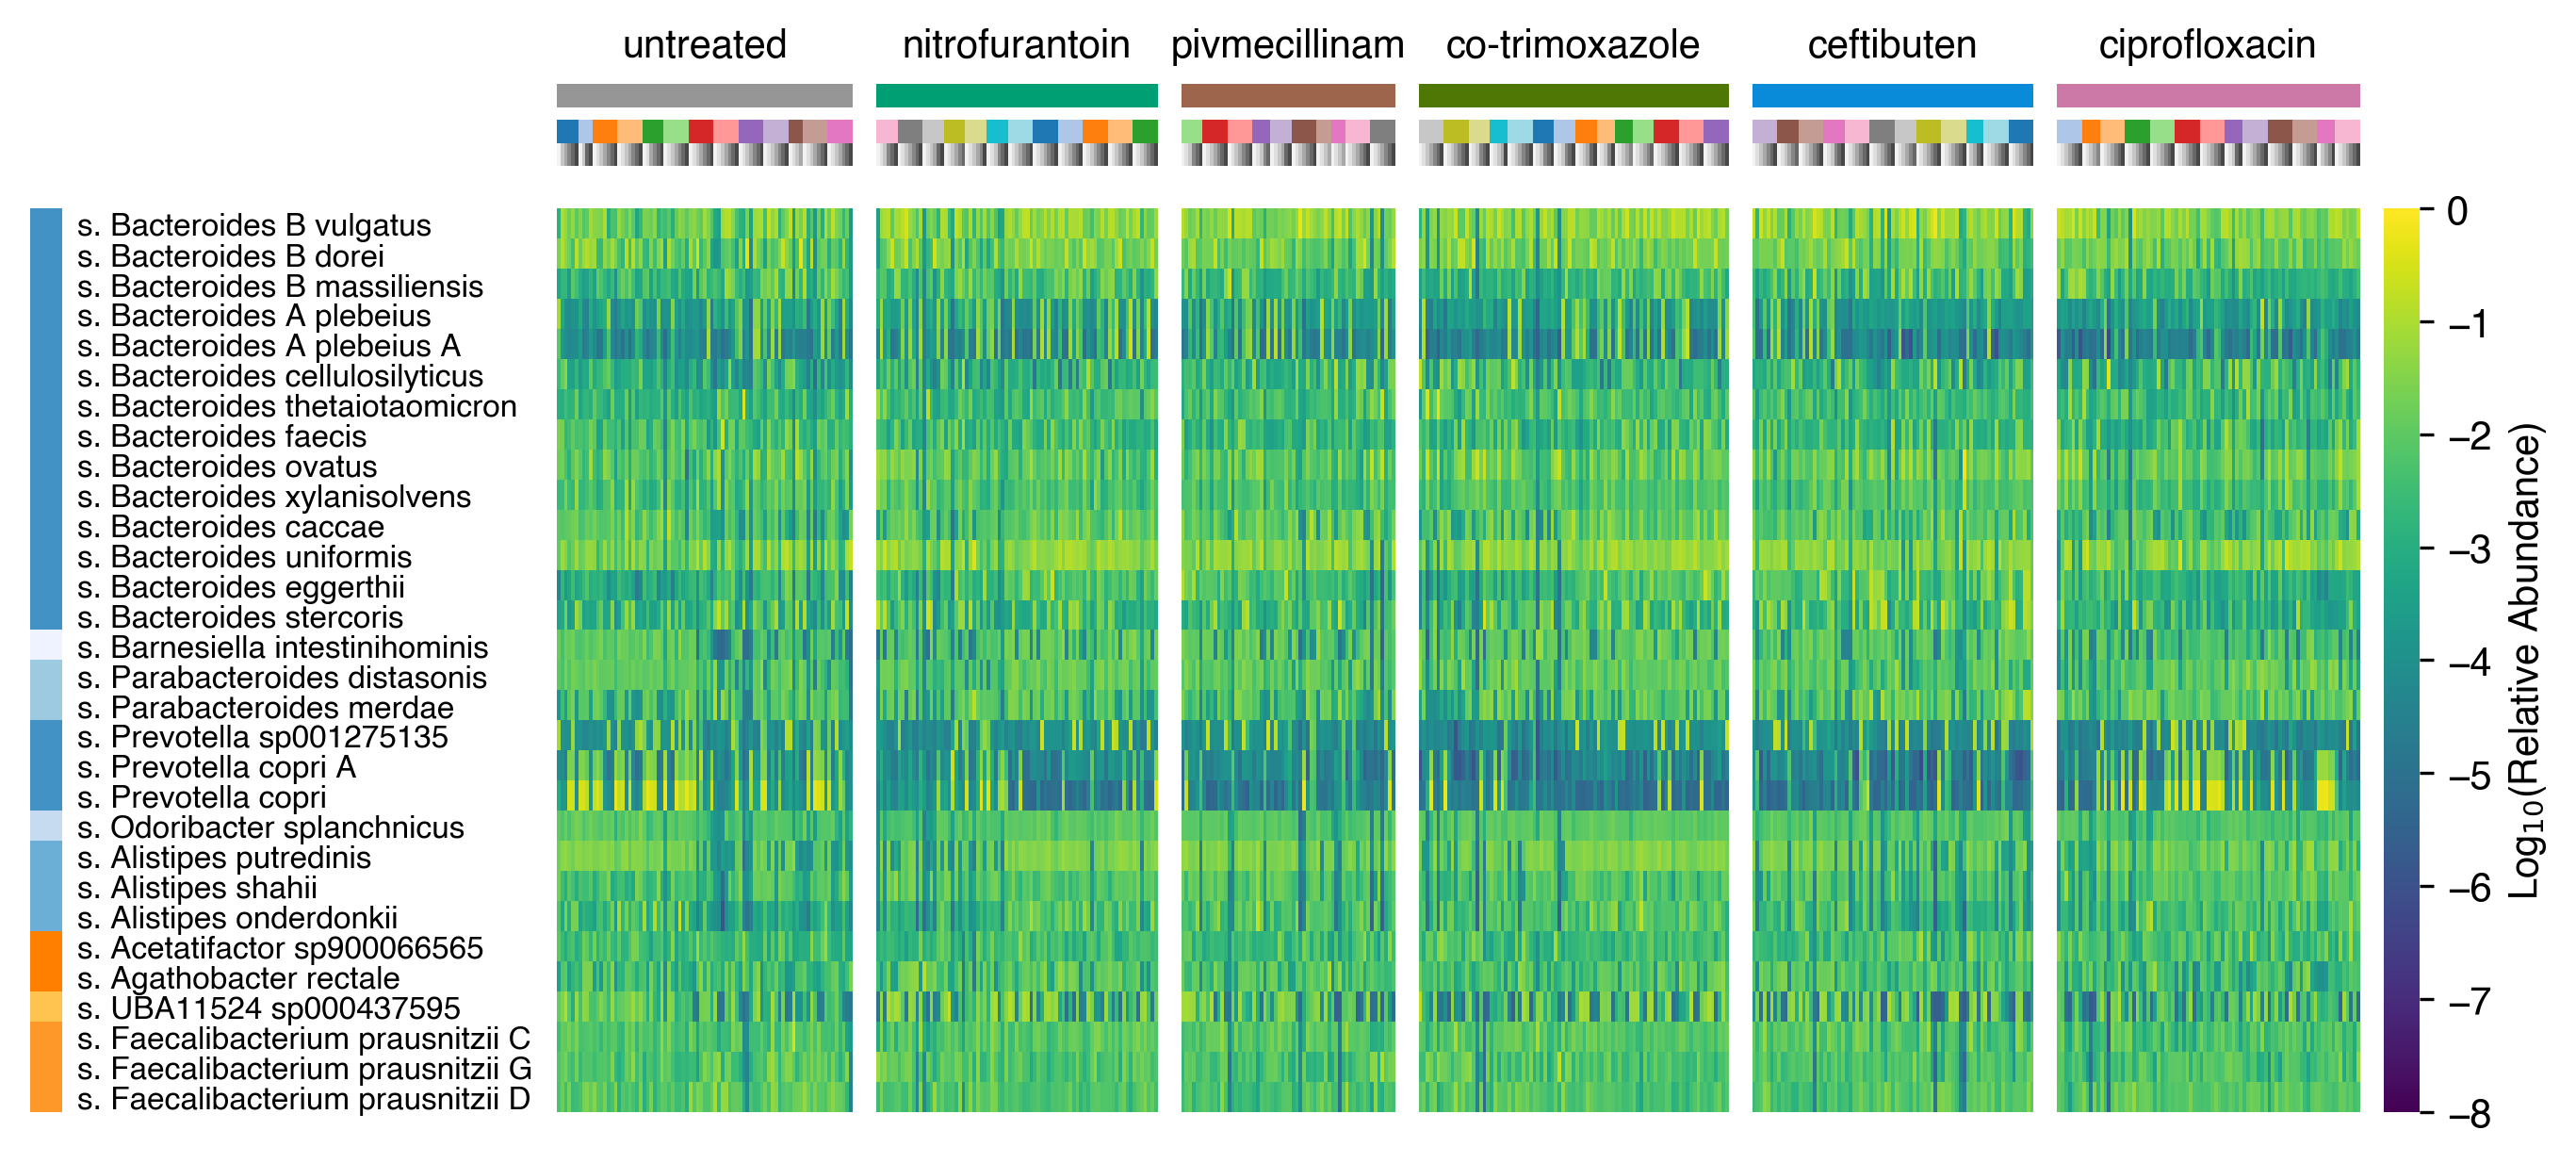

In [69]:
fig = plt.figure(dpi=300, constrained_layout=True, figsize=(9, 4), facecolor='None')
gs = fig.add_gridspec(2, 8, 
                      height_ratios=[1, 10],
                      width_ratios=np.hstack([10, count_size.values, 10]),
                      )
hm_kwrgs = dict(yticklabels=taxa_frame['species'],
                xticklabels=[],
                vmin=-8, vmax=0,
                cmap='viridis',
                )
axl = fig.add_subplot(gs[1, 0])
axl.bar(bottom=np.ones(len(taxa_frame)).cumsum() - 1,
        height=np.ones(len(taxa_frame)),
        color=taxa_frame['family_color'],
        x=np.zeros(len(taxa_frame)),
       )
axl.xaxis.set_tick_params(**hide_axes)
axl.yaxis.set_tick_params(**hide_axes)
axl.yaxis.set_tick_params(labelsize=8, labelright=True)
sn.despine(ax=axl, left=True, right=True, top=True, bottom=True)

cbar_ax = {'0': dict(cbar=True, cbar_ax=fig.add_subplot(gs[1, -1])),
           '1': dict(cbar=False, cbar_ax=None),
           '2': dict(cbar=False, cbar_ax=None),
           '3': dict(cbar=False, cbar_ax=None),
           '4': dict(cbar=False, cbar_ax=None),
           '5': dict(cbar=False, cbar_ax=None),
            }
for abx, abx_data in table3.T.groupby('abx_code2'):
    ax = fig.add_subplot(gs[1, int(abx) + 1], sharey=axl)
    sn.heatmap(ax=ax, data=abx_data.T, **hm_kwrgs, **cbar_ax[abx])
    ax.yaxis.get_label().set_visible(False)
    ax.xaxis.get_label().set_visible(False)
    ax.xaxis.set_tick_params(**hide_axes)
    ax.yaxis.set_tick_params(**hide_axes)
    ax.yaxis.set_tick_params(labelleft=False, labelsize=8)
    
    part_ = abx_data.index.to_frame()
    part_['x'] = 1
    part_['x'] = part_['x'].cumsum() - 1
    part_['time_color'] = part_['timepoint'].replace(time_colors)
    part_['abx_color'] = part_['abx_code2'].replace(abx_colors)
    part_['subject_color'] = part_['host_subject_id'].replace(subject_colors)

    axt = fig.add_subplot(gs[0, int(abx) + 1], facecolor='None', sharex=ax)
    axt.xaxis.set_tick_params(**hide_axes)
    axt.yaxis.set_tick_params(**hide_axes)
    sn.despine(ax=axt, left=True, right=True, top=True, bottom=True)
    axt.barh(left=part_['x'], 
             width=1,
             y=part_['x'] * 0 + 0.5,
             height=1, 
             color=part_['time_color'])
    axt.barh(left=part_['x'], 
             width=1,
             y=part_['x'] * 0 + 1.5,
             height=1, 
             color=part_['subject_color'])
    axt.barh(left=part_['x'], 
             width=1,
             y=part_['x'] * 0 + 3,
             height=1, 
             color=part_['abx_color'])
    axt.set_title(abx_names[abx], size=10)

cbar_ax['0']['cbar_ax'].set_ylabel('Log$_{10}$(Relative Abundance)')